# Etapa 1 - Configurações iniciais

## Instalando dependências

In [ ]:
!pip install ultralytics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 74.9 MB/s eta 0:00:00


In [ ]:
!pip install inference-sdk

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 60.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.5/62.5 MB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 212.4/212.4 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.9/50.9 kB 4.7 MB/s eta 0:00:00
  Attempting uninstall: opencv-python
    Found existing installation: opencv-python 4.12.0.88
    Uninstalling opencv-python-4.12.0.88:
      Successfully uninstalled opencv-python-4.12.0.88
  Attempting uninstall: aiohttp
    Found existing installation: aiohttp 3.13.2
    Uninstalling aiohttp-3.13.2:
      Successfully uninstalled aiohttp-3.13.2


In [ ]:
!pip install roboflow


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 21.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 46.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 87.0 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.12.0.88
    Uninstalling opencv-python-headless-4.12.0.88:
      Successfully uninstalled opencv-python-headless-4.12.0.88
  Attempting uninstall: idna
    Found existing installation: idna 3.11
    Uninstalling idna-3.11:
      Successfully uninstalled idna-3.11


In [ ]:
import ultralytics
from ultralytics import YOLO
from roboflow import Roboflow
import cv2
import matplotlib.pyplot as plt
import os
from IPython.display import display, Image

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
#Verificando instalção do YOLO
import ultralytics
ultralytics.checks()

Ultralytics 8.3.235 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 38.5/112.6 GB disk)


## Baixando dataset

In [ ]:
from roboflow import Roboflow
# Chave do Roboflow: lida da variável de ambiente ROBOFLOW_API_KEY ou,
# no Colab, de um secret com o mesmo nome (ícone de chave na barra lateral).
import os
api_key = os.environ.get("ROBOFLOW_API_KEY")
if not api_key:
    try:
        from google.colab import userdata
        api_key = userdata.get("ROBOFLOW_API_KEY")
    except ImportError:
        raise RuntimeError("Defina a variável de ambiente ROBOFLOW_API_KEY.")
rf = Roboflow(api_key=api_key)
project = rf.workspace("object-defect-1xn3t").project("pcb_detection-kecsf")
version = project.version(3)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to PCB_detection-3 in yolov8:: 100%|██████████| 3626/3626 [00:00<00:00, 7608.08it/s]


# Etapa 2 - Treinando o modelo 1.0

In [ ]:

# Carregando um modelo pré-treinado (Transfer Learning)
model = YOLO('yolov8n.pt') # 'n' de Nano (o mais leve)

# Iniciando o treinamento
results = model.train(
    data=f'{dataset.location}/data.yaml',
    epochs=100,
    imgsz=640,
    name='hawkeye_v1', # Nome do nosso projeto
    patience=10 # Se parar de melhorar por 10 épocas, ele encerra
)

Ultralytics 8.3.235 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/PCB_detection-3/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=hawkeye_v1, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=10, perspective=0.0, plots=Tru

## Carregando os pesos treinados

Os pesos do treino `hawkeye_v1` estão versionados em `weights/baseline/`. Esta célula permite pular o treino acima.

In [ ]:
# Caminho com os pesos do treinamento (relativo à raiz do repositório)
caminho_do_modelo = 'weights/baseline/best.pt'

# Carrega o hawkeye_v1
model = YOLO(caminho_do_modelo)
modelv1 = model

print("Modelo Hawkeye 1.0 recuperado com sucesso! Pronto para testes.")

Modelo Hawkeye 1.0 recuperado com sucesso! Pronto para testes.


# Etapa 3 - Testando o modelo 1.0

Testando em 262 imagens originais (Verdes)...

0: 640x640 2 mouse_bites, 3.4ms
1: 640x640 2 shorts, 3.4ms
2: 640x640 2 shorts, 3.4ms
3: 640x640 1 missing_hole, 3.4ms
4: 640x640 1 open_circuit, 3.4ms
5: 640x640 3 shorts, 3.4ms
6: 640x640 1 mouse_bite, 3.4ms
7: 640x640 2 missing_holes, 3.4ms
8: 640x640 3 missing_holes, 3.4ms
9: 640x640 3 missing_holes, 3.4ms
10: 640x640 2 open_circuits, 3.4ms
11: 640x640 1 missing_hole, 3.4ms
12: 640x640 1 open_circuit, 3.4ms
13: 640x640 1 short, 3.4ms
14: 640x640 1 open_circuit, 3.4ms
15: 640x640 2 open_circuits, 3.4ms
16: 640x640 2 shorts, 3.4ms
17: 640x640 1 open_circuit, 3.4ms
18: 640x640 1 short, 3.4ms
19: 640x640 1 short, 3.4ms
20: 640x640 1 open_circuit, 3.4ms
21: 640x640 2 shorts, 3.4ms
22: 640x640 1 open_circuit, 3.4ms
23: 640x640 1 short, 3.4ms
24: 640x640 1 open_circuit, 3.4ms
25: 640x640 4 shorts, 3.4ms
26: 640x640 1 mouse_bite, 3.4ms
27: 640x640 1 open_circuit, 3.4ms
28: 640x640 1 short, 3.4ms
29: 640x640 1 short, 3.4ms
30: 640x640 2 shorts,

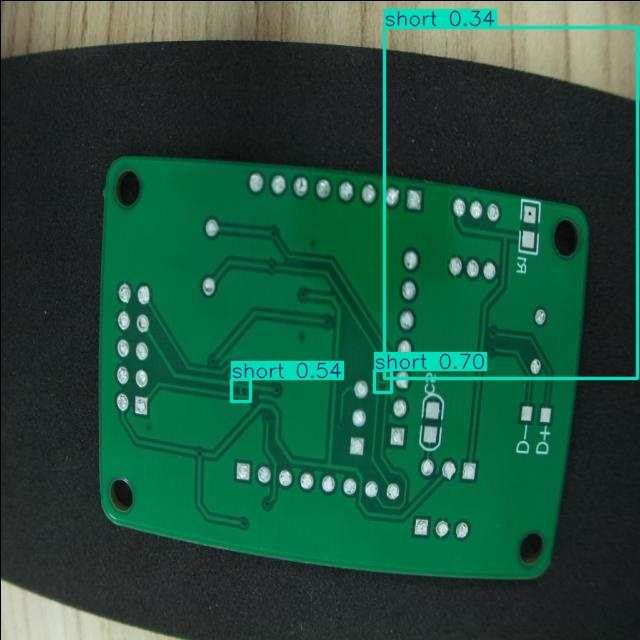

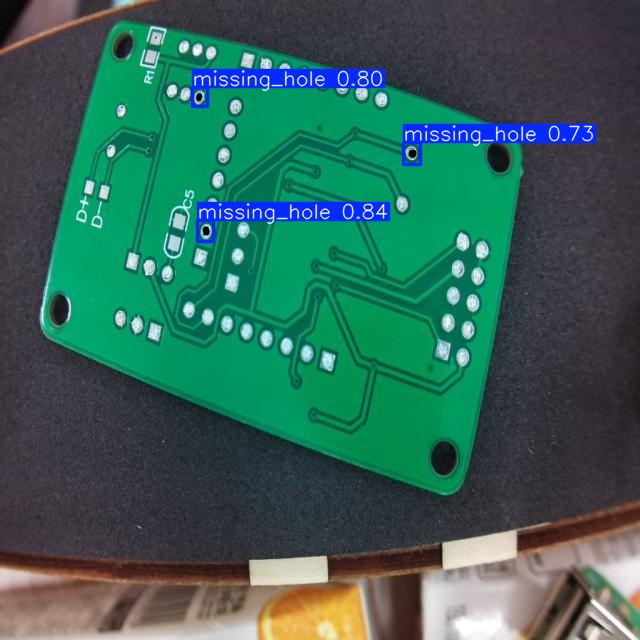

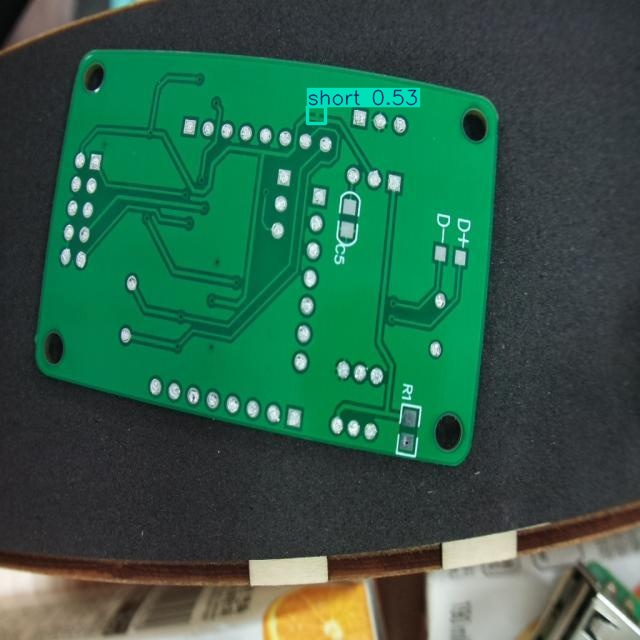

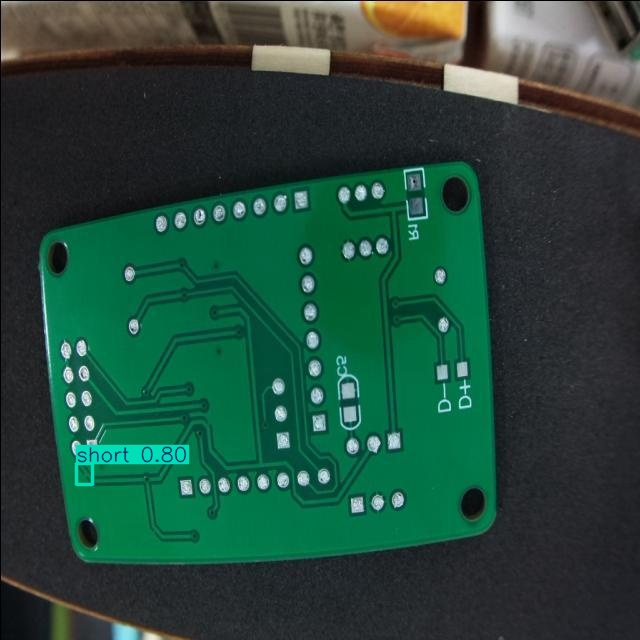

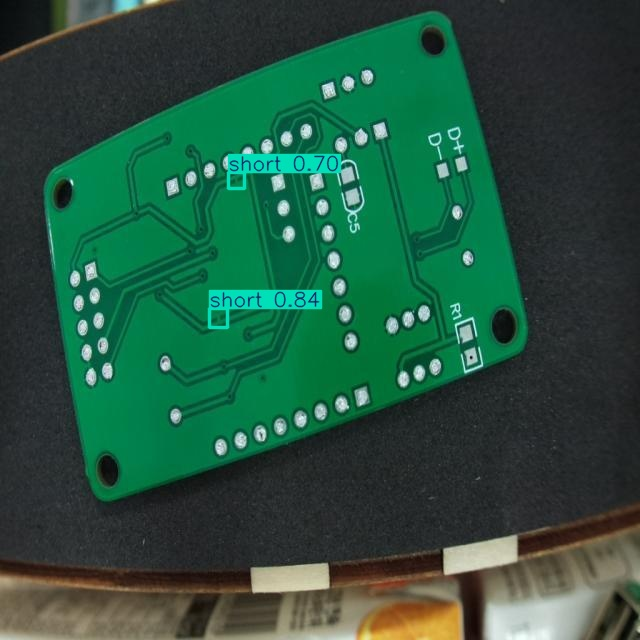

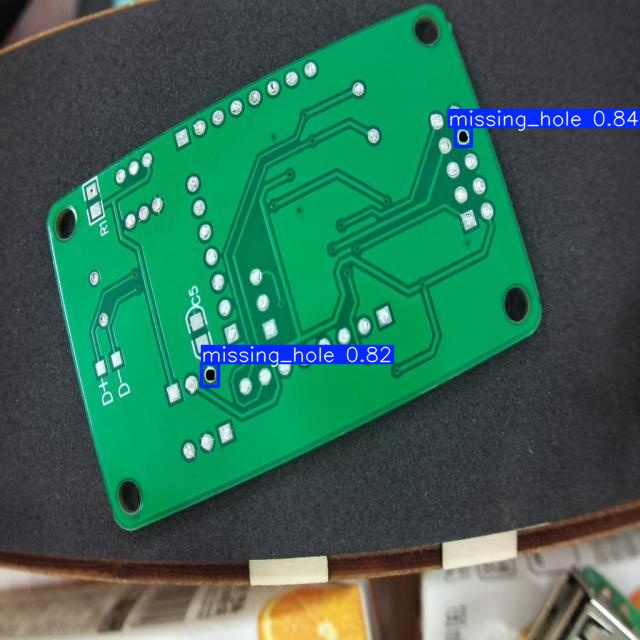

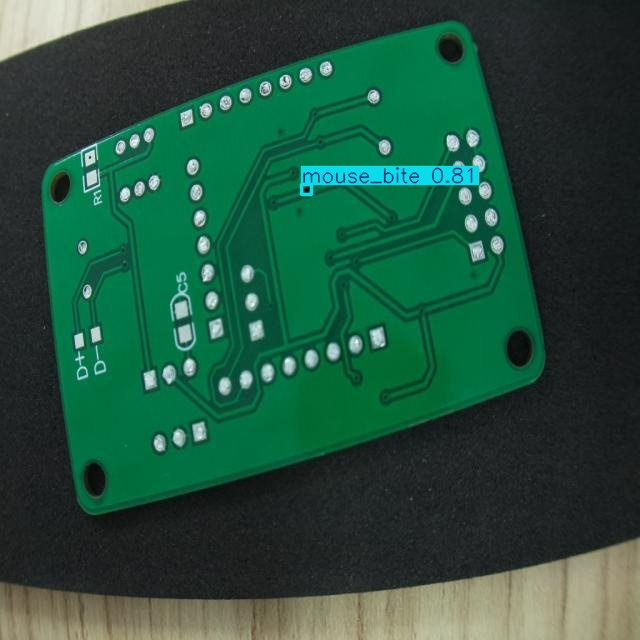

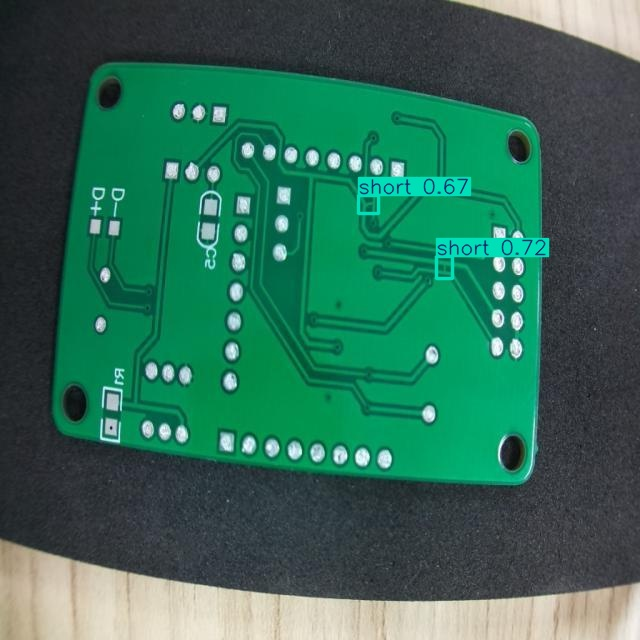

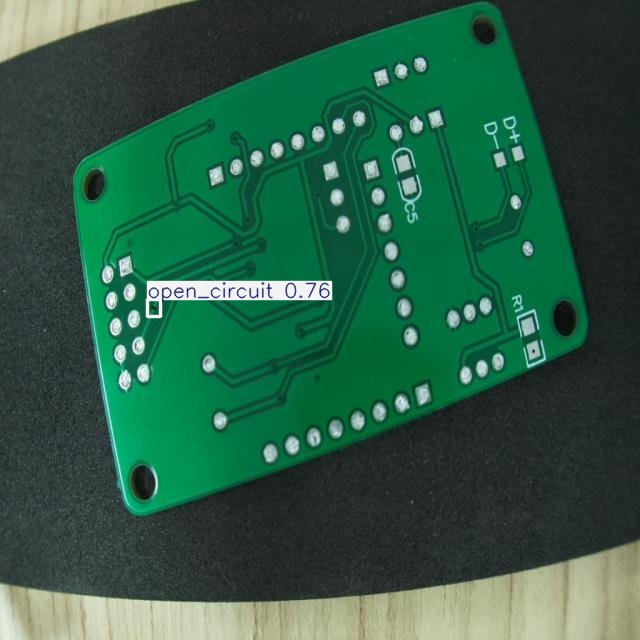

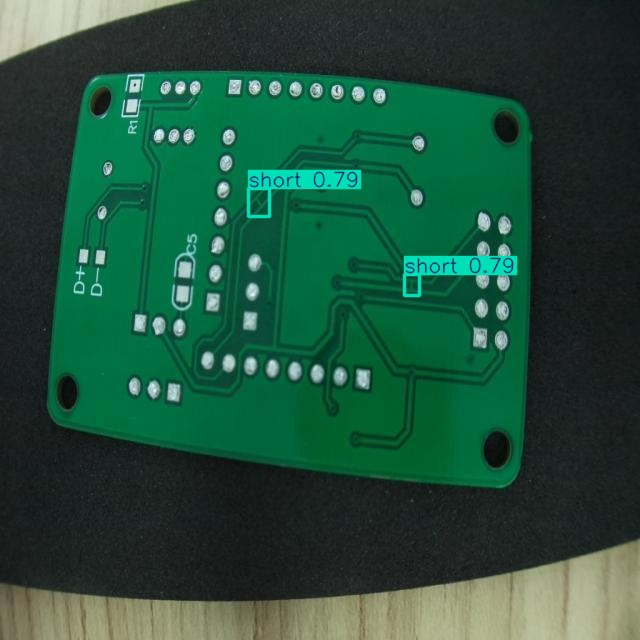

In [ ]:
# Teste na Base Original
import glob
import random

# Imagens da pasta de TESTE
test_images = glob.glob(f'{dataset.location}/test/images/*.jpg')

# Vamos escolher 10 imagens aleatórias para exibir
random_images = random.sample(test_images, 10)

print(f"Testando em {len(test_images)} imagens originais (Verdes)...")

# Rodar a predição
# save=True vai salvar as imagens desenhadas na pasta runs/detect/teste_original
results_original = model.predict(source=test_images, conf=0.6, save=True, project="runs/detect", name="teste_original")

# Mostrar 10 exemplos na tela para a gente ver o sucesso
print("\n--- RESULTADO NO DATASET ORIGINAL (Expectativa: Sucesso) ---")
for img_path in random_images:
    # O YOLO salva o resultado com o mesmo nome do arquivo original
    nome_arquivo = os.path.basename(img_path)
    caminho_resultado = f'runs/detect/teste_original/{nome_arquivo}'
    display(Image(filename=caminho_resultado, width=400))

In [ ]:
print(f"{'ID':<10} | {'CLASSE':<15} | {'CONFIANÇA'}")
print("-" * 40)

# O enumerate(results_original) entrega o número (i) e o conteúdo (result)
for i, result in enumerate(results_original):

    # Se a imagem não tiver defeito nenhum
    if len(result.boxes) == 0:
         print(f"imagem {i:<3} | {'--- OK ---':<15} | 100.0%")

    for box in result.boxes:
        classe_id = int(box.cls[0])
        nome_classe = model.names[classe_id]
        confianca = float(box.conf[0])

        print(f"imagem {i:<3} | {nome_classe:<15} | {confianca:.1%}")

ID         | CLASSE          | CONFIANÇA
----------------------------------------
imagem 0   | mouse_bite      | 76.0%
imagem 0   | mouse_bite      | 51.2%
imagem 1   | short           | 74.2%
imagem 1   | short           | 71.7%
imagem 2   | short           | 80.8%
imagem 2   | short           | 80.2%
imagem 3   | missing_hole    | 80.0%
imagem 4   | open_circuit    | 72.7%
imagem 5   | short           | 75.6%
imagem 5   | short           | 46.8%
imagem 5   | short           | 37.7%
imagem 6   | mouse_bite      | 76.9%
imagem 7   | missing_hole    | 85.0%
imagem 7   | missing_hole    | 77.7%
imagem 8   | missing_hole    | 84.6%
imagem 8   | missing_hole    | 84.6%
imagem 8   | missing_hole    | 83.4%
imagem 9   | missing_hole    | 84.3%
imagem 9   | missing_hole    | 80.0%
imagem 9   | missing_hole    | 72.7%
imagem 10  | open_circuit    | 72.8%
imagem 10  | open_circuit    | 66.3%
imagem 11  | missing_hole    | 83.8%
imagem 12  | open_circuit    | 74.8%
imagem 13  | short           |

# Etapa 4 - Métricas do Teste

In [ ]:
# Calcula o mAP do Cenário A
print("Calculando as métricas do Hawkeye 1.0 ...\n")

metrics = model.val(
    data=f'{dataset.location}/data.yaml',
    split='test',       # Usa a pasta de teste oficial
    project="runs/val",
    name="cenario_A_original"
)

print("\n" + "="*40)
print(f"RESULTADO OFICIAL (Cenário A):")
print(f"mAP50: {metrics.box.map50:.1%}")
print(f"Recall: {metrics.box.mr:.1%}")
print(f"Precisão: {metrics.box.mp:.1%}")
print("="*40)

Calculando as métricas do Hawkeye 1.0 ...

Ultralytics 8.3.235 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 779.7±193.3 MB/s, size: 55.5 KB)
val: Scanning /content/PCB_detection-3/test/labels... 262 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 262/262 2.2Kit/s 0.1s
val: New cache created: /content/PCB_detection-3/test/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 144, len(boxes) = 393. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 3.8it/s 4.5s
                   all        262        393      0.916        0.9      0.929        0.5
          missing_hole         60        117      0.945      0.949      0.974      0.659
            mou

# Etapa 5 Under fitting

## Treinamento com um baixo número de épocas

In [ ]:

# Carregando um modelo pré-treinado (Transfer Learning)
model = YOLO('yolov8n.pt') # 'n' de Nano (o mais leve)

# Iniciando o treinamento
results = model.train(
    data=f'{dataset.location}/data.yaml',
    epochs=2,
    imgsz=640,
    name='hawkeye_v3Under', # Nome do nosso projeto
)

Ultralytics 8.3.235 🚀 Python-3.12.12 torch-2.9.0+cu126 CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/PCB_detection-3/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=hawkeye_v3Under, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, p

## Carregando os pesos treinados

Os pesos do treino `hawkeye_v3Under` estão versionados em `weights/underfit/`. Esta célula permite pular o treino acima.

In [ ]:
# Caminho com os pesos do treinamento (relativo à raiz do repositório)
caminho_do_modelo = 'weights/underfit/best.pt'

# Carrega o hawkeye_v3
model = YOLO(caminho_do_modelo)

print("Modelo Hawkeye 3.0 recuperado com sucesso! Pronto para testes.")

Modelo Hawkeye 3.0 recuperado com sucesso! Pronto para testes.


## Testando o modelo com poucas épocas

Testando em 262 imagens originais (Verdes)...

0: 640x640 (no detections), 3.4ms
1: 640x640 (no detections), 3.4ms
2: 640x640 (no detections), 3.4ms
3: 640x640 1 missing_hole, 3.4ms
4: 640x640 (no detections), 3.4ms
5: 640x640 (no detections), 3.4ms
6: 640x640 (no detections), 3.4ms
7: 640x640 2 missing_holes, 3.4ms
8: 640x640 (no detections), 3.4ms
9: 640x640 2 missing_holes, 3.4ms
10: 640x640 (no detections), 3.4ms
11: 640x640 (no detections), 3.4ms
12: 640x640 (no detections), 3.4ms
13: 640x640 (no detections), 3.4ms
14: 640x640 (no detections), 3.4ms
15: 640x640 (no detections), 3.4ms
16: 640x640 (no detections), 3.4ms
17: 640x640 (no detections), 3.4ms
18: 640x640 (no detections), 3.4ms
19: 640x640 (no detections), 3.4ms
20: 640x640 (no detections), 3.4ms
21: 640x640 (no detections), 3.4ms
22: 640x640 (no detections), 3.4ms
23: 640x640 (no detections), 3.4ms
24: 640x640 (no detections), 3.4ms
25: 640x640 (no detections), 3.4ms
26: 640x640 (no detections), 3.4ms
27: 640x640 (no det

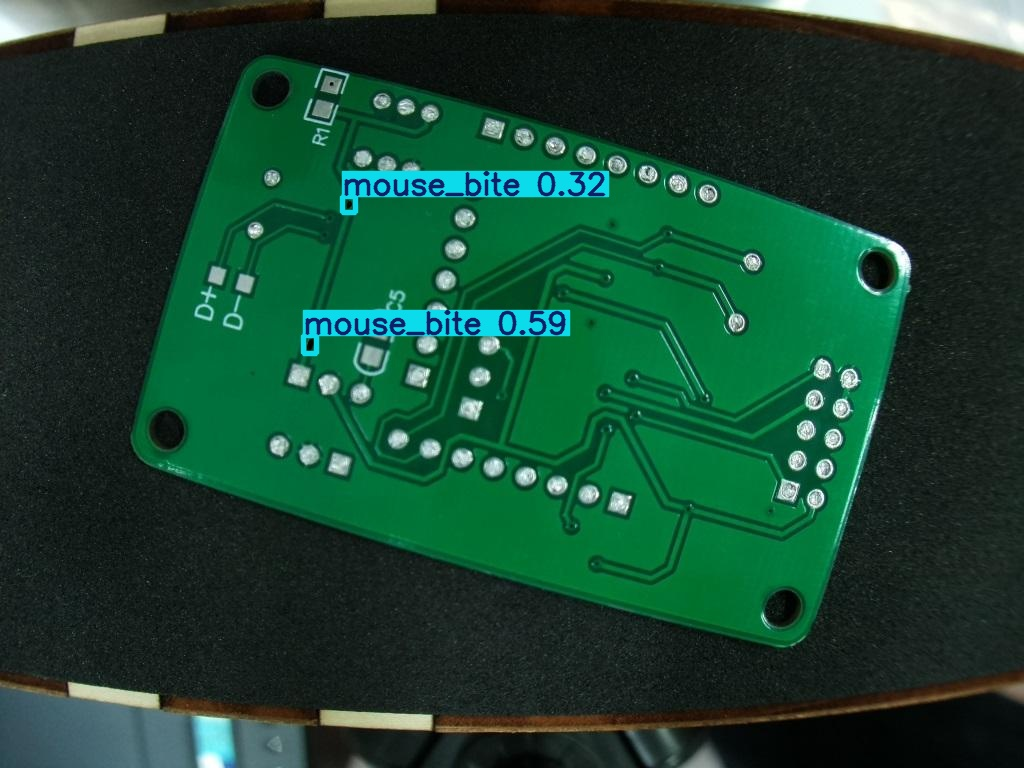

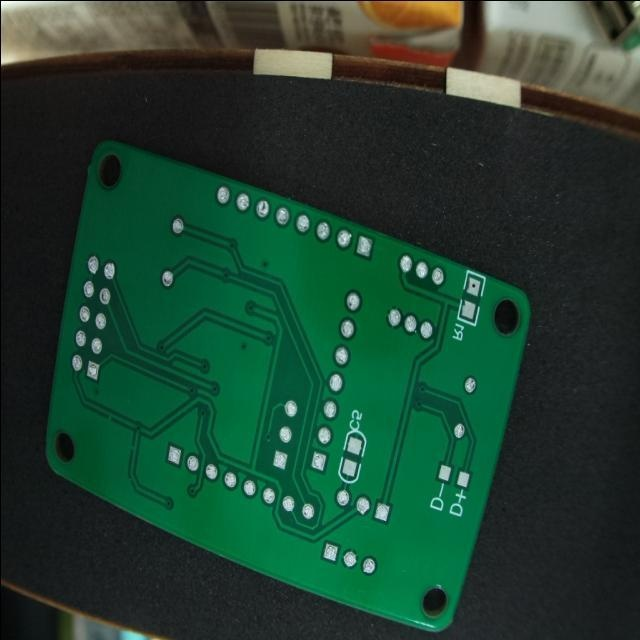

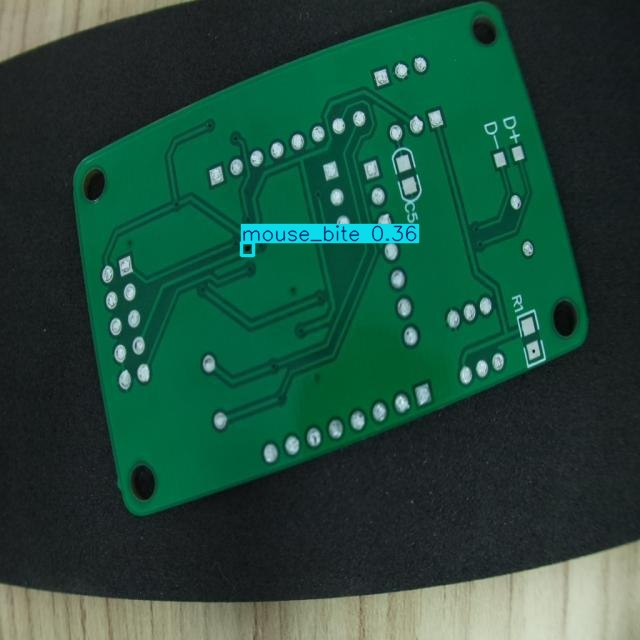

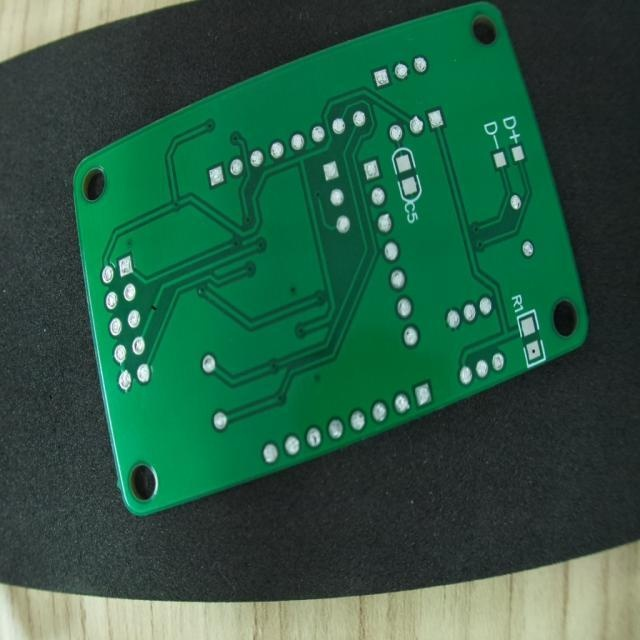

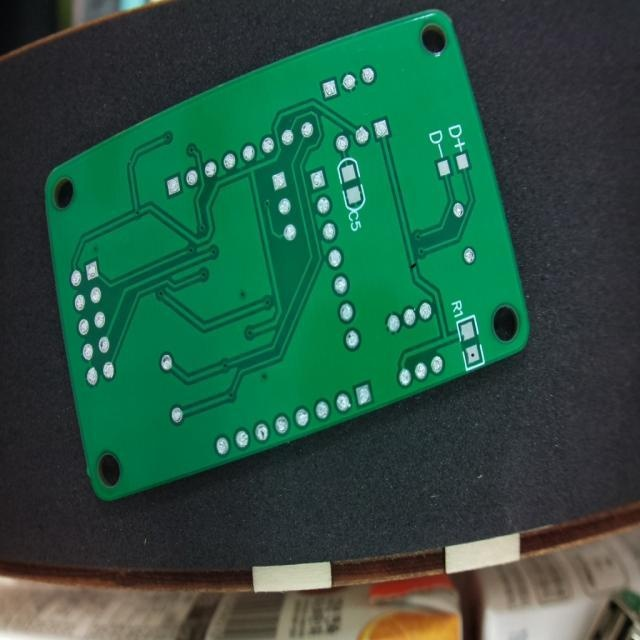

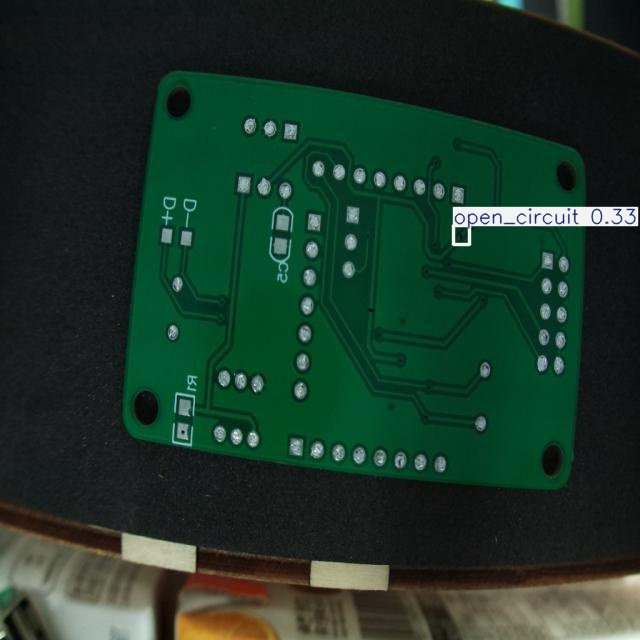

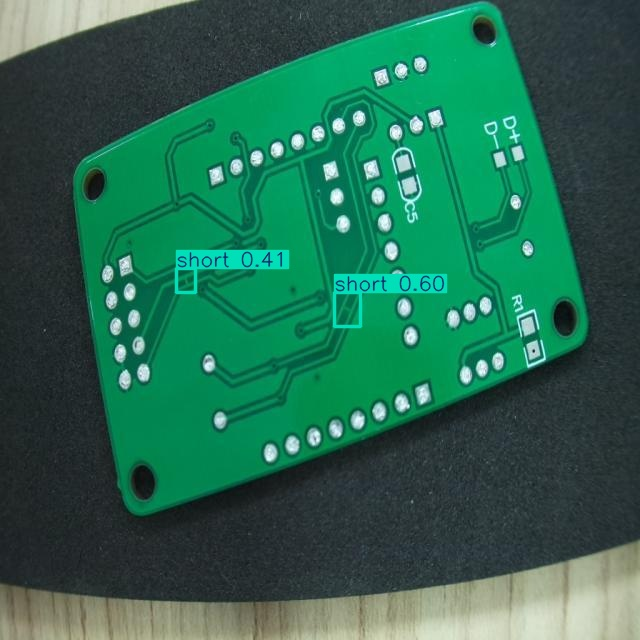

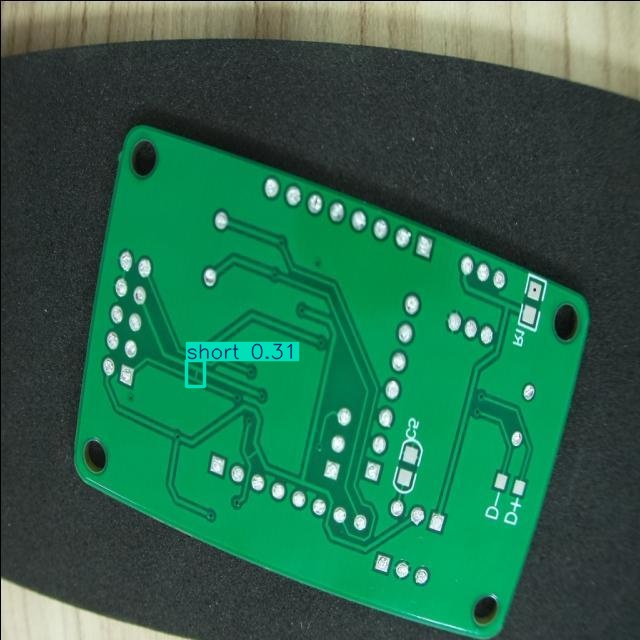

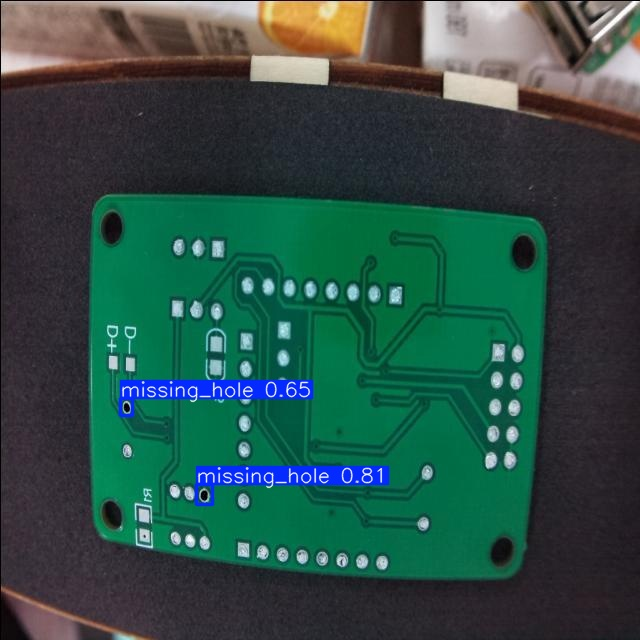

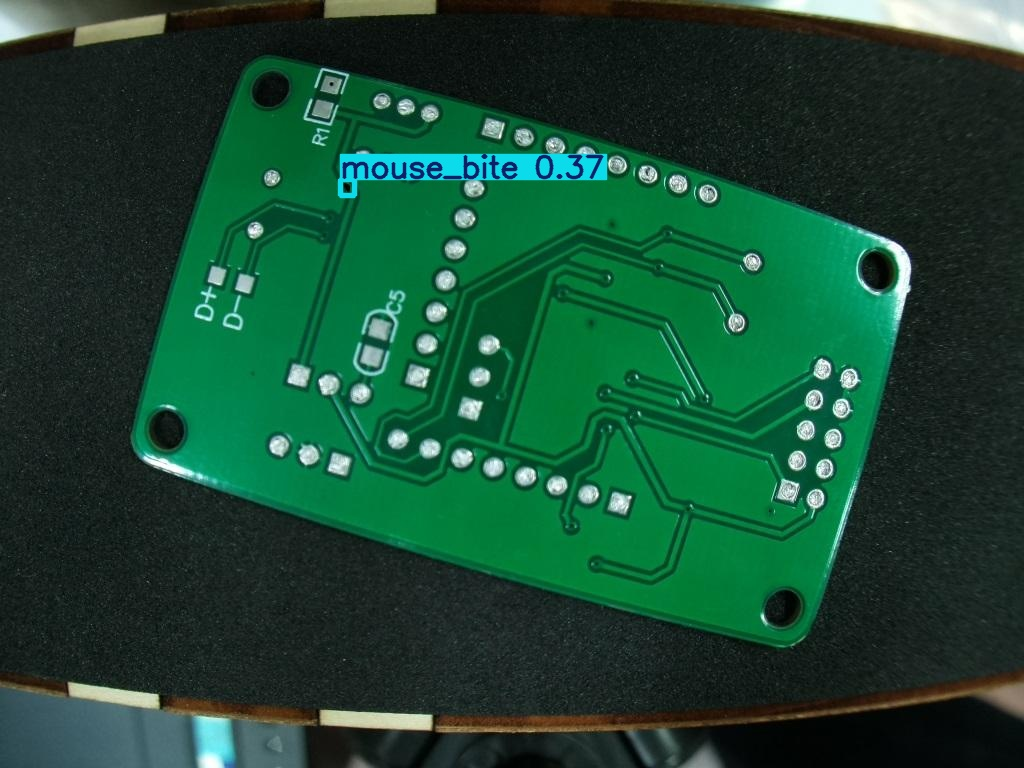

In [ ]:
# Teste na Base Original
import glob
import random

# Imagens da pasta de TESTE
test_images = glob.glob(f'{dataset.location}/test/images/*.jpg')

# Vamos escolher 3 imagens aleatórias para exibir
random_images = random.sample(test_images, 10)

print(f"Testando em {len(test_images)} imagens originais (Verdes)...")

# Rodar a predição
# save=True vai salvar as imagens desenhadas na pasta runs/detect/teste_original
results_original = model.predict(source=test_images, conf=0.25, save=True, project="runs/detect", name="teste_underfit")

# Mostrar 10 exemplos na tela para a gente ver o sucesso
print("\n--- RESULTADO UNDERFITTING NO DATASET ORIGINAL (Expectativa: Falhas) ---")
for img_path in random_images:
    # O YOLO salva o resultado com o mesmo nome do arquivo original
    nome_arquivo = os.path.basename(img_path)
    caminho_resultado = f'runs/detect/teste_underfit/{nome_arquivo}'
    display(Image(filename=caminho_resultado, width=640))

In [ ]:
print(f"{'ID':<10} | {'CLASSE':<15} | {'CONFIANÇA'}")
print("-" * 40)

# O enumerate(results_original) entrega o número (i) e o conteúdo (result)
for i, result in enumerate(results_original):

    # Se a imagem não tiver defeito nenhum
    if len(result.boxes) == 0:
         print(f"imagem {i:<3} | {'--- OK ---':<15} | 100.0%")

    for box in result.boxes:
        classe_id = int(box.cls[0])
        nome_classe = model.names[classe_id]
        confianca = float(box.conf[0])

        print(f"imagem {i:<3} | {nome_classe:<15} | {confianca:.1%}")

ID         | CLASSE          | CONFIANÇA
----------------------------------------
imagem 0   | --- OK ---      | 100.0%
imagem 1   | --- OK ---      | 100.0%
imagem 2   | --- OK ---      | 100.0%
imagem 3   | missing_hole    | 40.4%
imagem 4   | --- OK ---      | 100.0%
imagem 5   | --- OK ---      | 100.0%
imagem 6   | --- OK ---      | 100.0%
imagem 7   | missing_hole    | 50.0%
imagem 7   | missing_hole    | 34.2%
imagem 8   | --- OK ---      | 100.0%
imagem 9   | missing_hole    | 68.2%
imagem 9   | missing_hole    | 36.4%
imagem 10  | --- OK ---      | 100.0%
imagem 11  | --- OK ---      | 100.0%
imagem 12  | --- OK ---      | 100.0%
imagem 13  | --- OK ---      | 100.0%
imagem 14  | --- OK ---      | 100.0%
imagem 15  | --- OK ---      | 100.0%
imagem 16  | --- OK ---      | 100.0%
imagem 17  | --- OK ---      | 100.0%
imagem 18  | --- OK ---      | 100.0%
imagem 19  | --- OK ---      | 100.0%
imagem 20  | --- OK ---      | 100.0%
imagem 21  | --- OK ---      | 100.0%
imagem 22  

## Métricas

In [ ]:
# Calcula o mAP do Cenário Underfitting
print("Calculando as métricas do Hawkeye 3.0 ...\n")

metrics = model.val(
    data=f'{dataset.location}/data.yaml',
    split='test',       # Usa a pasta de teste oficial
    project="runs/val",
    name="cenario_Underfitting"
)

print("\n" + "="*40)
print(f"RESULTADO OFICIAL (Cenário Underfitting):")
print(f"mAP50: {metrics.box.map50:.1%}")
print(f"Recall: {metrics.box.mr:.1%}")
print(f"Precisão: {metrics.box.mp:.1%}")
print("="*40)

Calculando as métricas do Hawkeye 3.0 ...

Ultralytics 8.3.235 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1053.0±417.6 MB/s, size: 43.5 KB)
val: Scanning /content/PCB_detection-3/test/labels.cache... 262 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 262/262 523.3Kit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 144, len(boxes) = 393. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 4.4it/s 3.9s
                   all        262        393      0.753      0.314      0.461      0.202
          missing_hole         60        117       0.89       0.94      0.909      0.494
            mouse_bite         63         80      0.536      0.231       

# Etapa 6 Overfitting (Alongando treinamento)


## Alongando treinamento

In [ ]:
longer = model.train(
    data=f'{dataset.location}/data.yaml',
    epochs=300,
    imgsz=640,
    name='hawkeye_v2', # Nome do nosso projeto
)

Ultralytics 8.3.235 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/PCB_detection-3/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=300, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/99best.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=hawkeye_v2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0

## Carregando os pesos treinados

Os pesos do treino `hawkeye_v2` estão versionados em `weights/overfit/`. Esta célula permite pular o treino acima.

In [ ]:
# Alongando o treinamento para 500 épocas

# Caminho com os pesos do treinamento (relativo à raiz do repositório)
caminho_do_modelo = 'weights/overfit/last.pt'

# Carrega o hawkeye_v1
model = YOLO(caminho_do_modelo)

print("Modelo Hawkeye 2.0 recuperado com sucesso! Pronto para testes.")

Modelo Hawkeye 2.0 recuperado com sucesso! Pronto para testes.


## Baixando dataset com modificações manuais

In [ ]:
from roboflow import Roboflow
# Chave do Roboflow: lida da variável de ambiente ROBOFLOW_API_KEY ou,
# no Colab, de um secret com o mesmo nome (ícone de chave na barra lateral).
import os
api_key = os.environ.get("ROBOFLOW_API_KEY")
if not api_key:
    try:
        from google.colab import userdata
        api_key = userdata.get("ROBOFLOW_API_KEY")
    except ImportError:
        raise RuntimeError("Defina a variável de ambiente ROBOFLOW_API_KEY.")
rf = Roboflow(api_key=api_key)
project = rf.workspace("david-pxvk6").project("pcb-alterado")
version = project.version(2)
datasetM = version.download("yolov8")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to PCB-Alterado-2 in yolov8:: 100%|██████████| 18/18 [00:00<00:00, 4323.03it/s]


## Teste dataset modificado


0: 640x640 1 open_circuit, 6.3ms
1: 640x640 2 open_circuits, 6.3ms
2: 640x640 1 open_circuit, 6.3ms
3: 640x640 3 open_circuits, 6.3ms
4: 640x640 1 open_circuit, 6.3ms
5: 640x640 2 mouse_bites, 1 open_circuit, 6.3ms
Speed: 2.2ms preprocess, 6.3ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/teste_overfit

--- RESULTADO OVERFITTING NO DATASET MODIFICADO (Expectativa: Falhas) ---


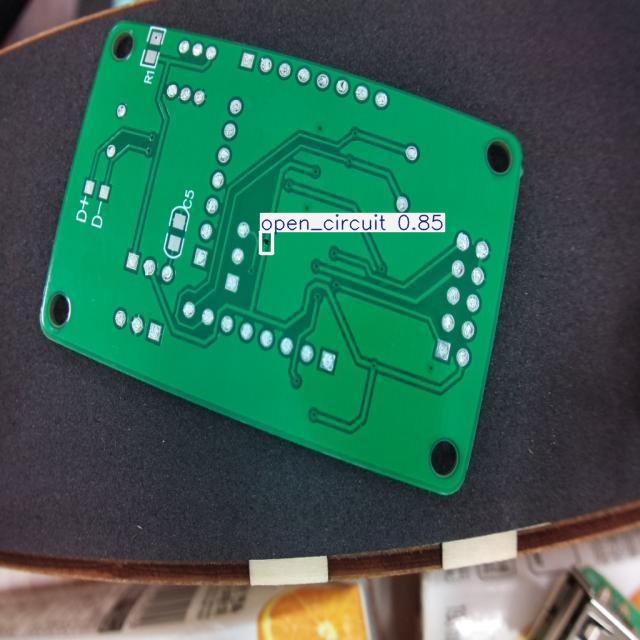

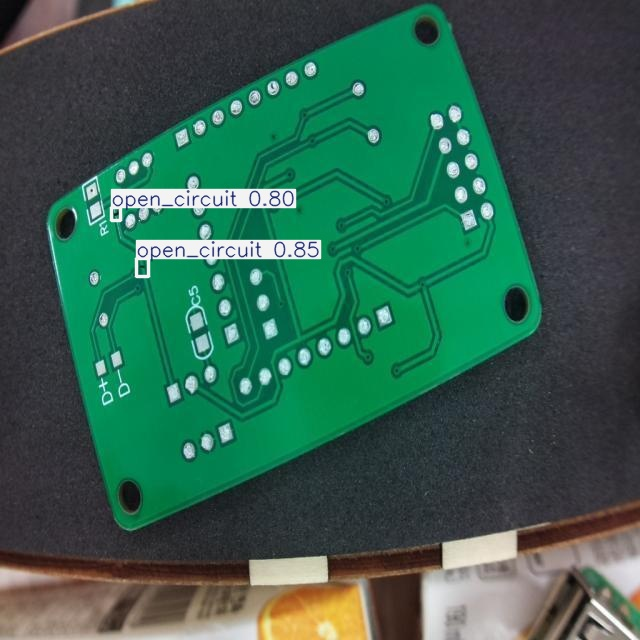

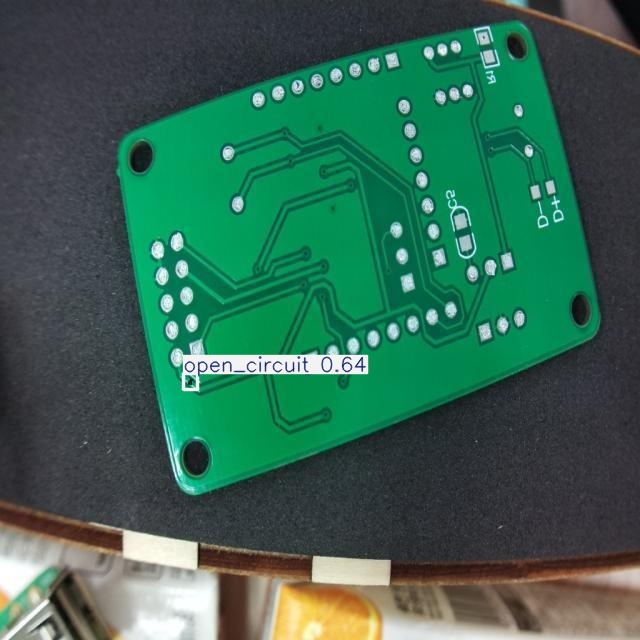

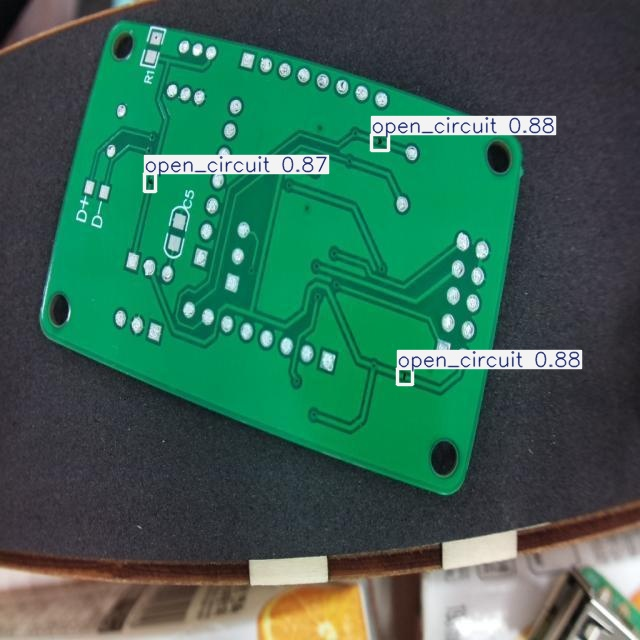

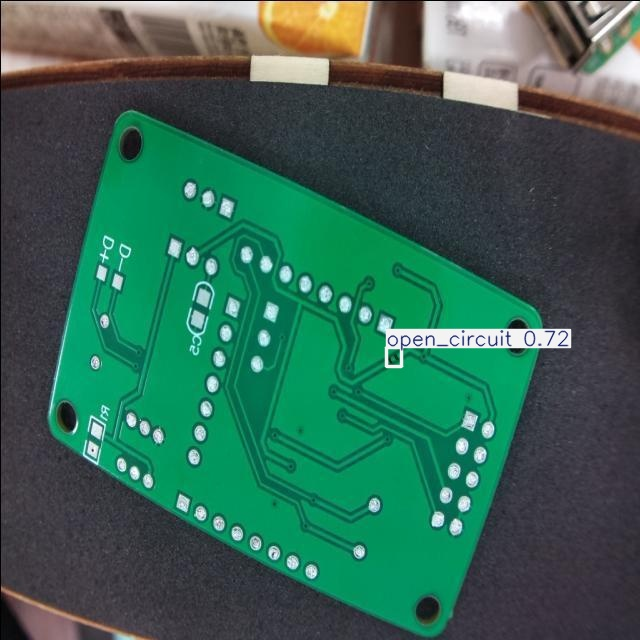

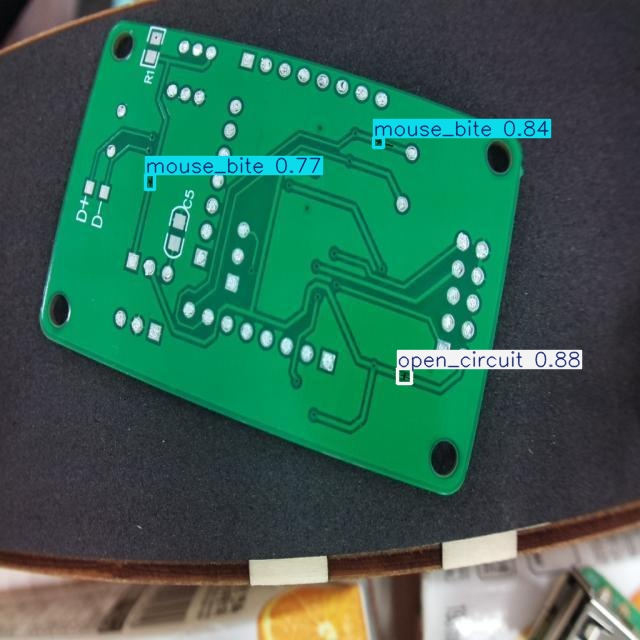

In [ ]:
# Teste na Base Modificada
import glob
import random

# Imagens da pasta de TESTE
test_images = glob.glob(f'{datasetM.location}/test/images/*.jpg')

results_original = model.predict(source=test_images, conf=0.25, save=True, project="runs/detect", name="teste_overfit")

# Mostrar 3 exemplos na tela para a gente ver o sucesso
print("\n--- RESULTADO OVERFITTING NO DATASET MODIFICADO (Expectativa: Falhas) ---")
for img_path in test_images:
    # O YOLO salva o resultado com o mesmo nome do arquivo original
    nome_arquivo = os.path.basename(img_path)
    caminho_resultado = f'runs/detect/teste_overfit/{nome_arquivo}'
    display(Image(filename=caminho_resultado, width=640))

In [ ]:
print(f"{'ID':<10} | {'CLASSE':<15} | {'CONFIANÇA'}")
print("-" * 40)

# O enumerate(results_original) entrega o número (i) e o conteúdo (result)
for i, result in enumerate(results_original):

    # Se a imagem não tiver defeito nenhum
    if len(result.boxes) == 0:
         print(f"imagem {i:<3} | {'--- OK ---':<15} | 100.0%")

    for box in result.boxes:
        classe_id = int(box.cls[0])
        nome_classe = model.names[classe_id]
        confianca = float(box.conf[0])

        print(f"imagem {i:<3} | {nome_classe:<15} | {confianca:.1%}")

ID         | CLASSE          | CONFIANÇA
----------------------------------------
imagem 0   | open_circuit    | 84.7%
imagem 1   | open_circuit    | 85.3%
imagem 1   | open_circuit    | 79.8%
imagem 2   | open_circuit    | 63.7%
imagem 3   | open_circuit    | 88.5%
imagem 3   | open_circuit    | 87.8%
imagem 3   | open_circuit    | 86.8%
imagem 4   | open_circuit    | 72.2%
imagem 5   | open_circuit    | 87.9%
imagem 5   | mouse_bite      | 84.4%
imagem 5   | mouse_bite      | 76.6%


# Etapa 7 - Overfitting (Placas Vermelhas)

1. Preparando o terreno...

   -> Pasta 'dataset_sabotado/images' criada com sucesso.
   -> Pasta 'dataset_sabotado/labels' criada com sucesso.

2. Processando 262 imagens originais...
   (Alterando cor de Verde para Vermelho ...)


100%|██████████| 262/262 [00:02<00:00, 116.75it/s]



3. Copiando os gabaritos (.txt)...
   -> 262 arquivos de gabarito copiados.

4. Criando arquivo de configuração 'sabotado.yaml'...

5. Calculando métricas do Cenário B...

Ultralytics 8.3.235 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1777.0±514.6 MB/s, size: 80.1 KB)


val: Scanning /content/dataset_sabotado/labels... 262 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 262/262 2.1Kit/s 0.1s
val: New cache created: /content/dataset_sabotado/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 144, len(boxes) = 393. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 4.8it/s 3.6s
                   all        262        393     0.0239     0.0674     0.0297     0.0177
          missing_hole         60        117     0.0886      0.239      0.115     0.0688
            mouse_bite         63         80          0          0          0          0
          open_circuit         74         94    0.00181     0.0106    0.00094    0.00047
                 short         65        102    0.0049

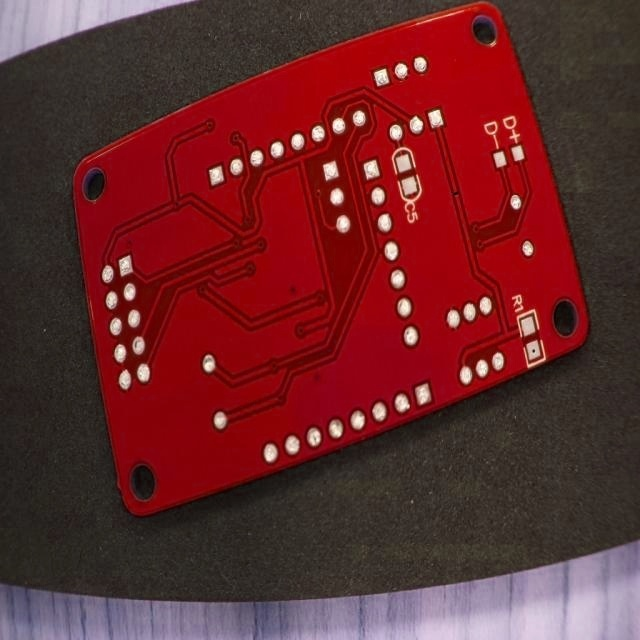

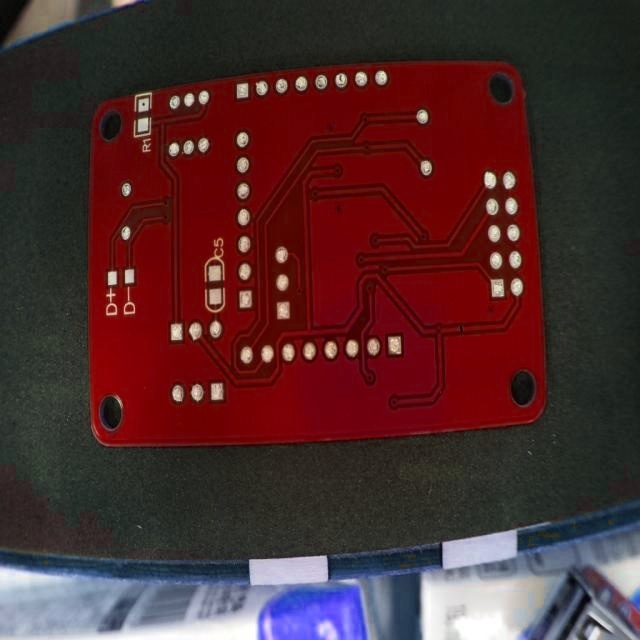

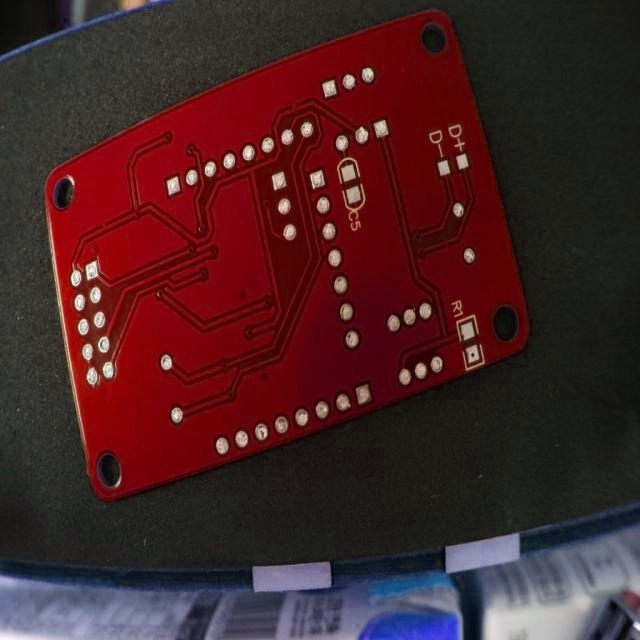

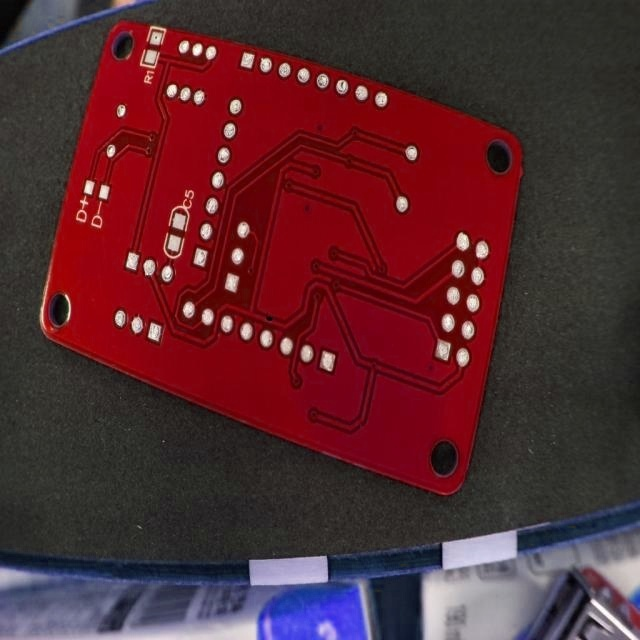

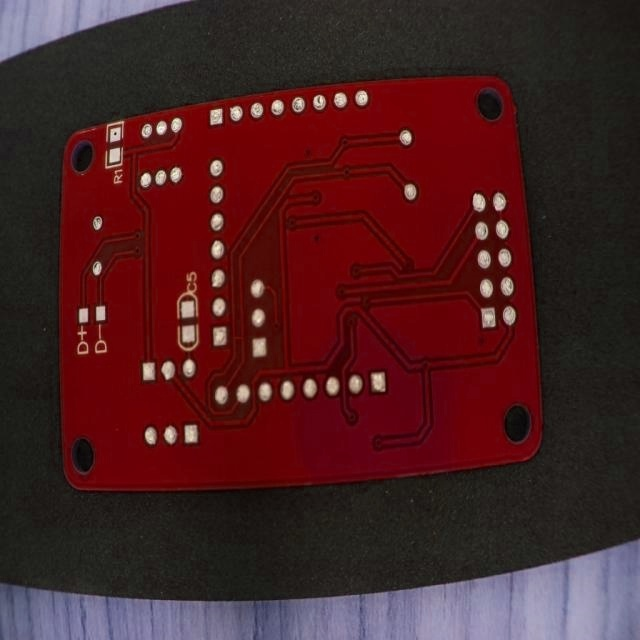

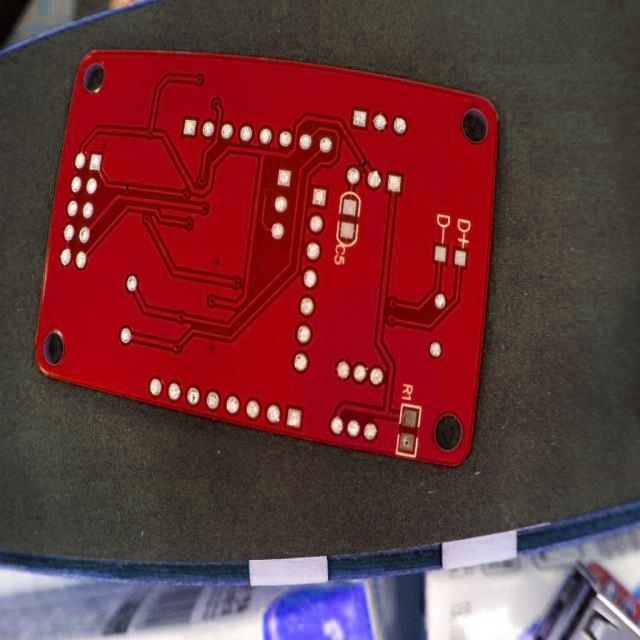

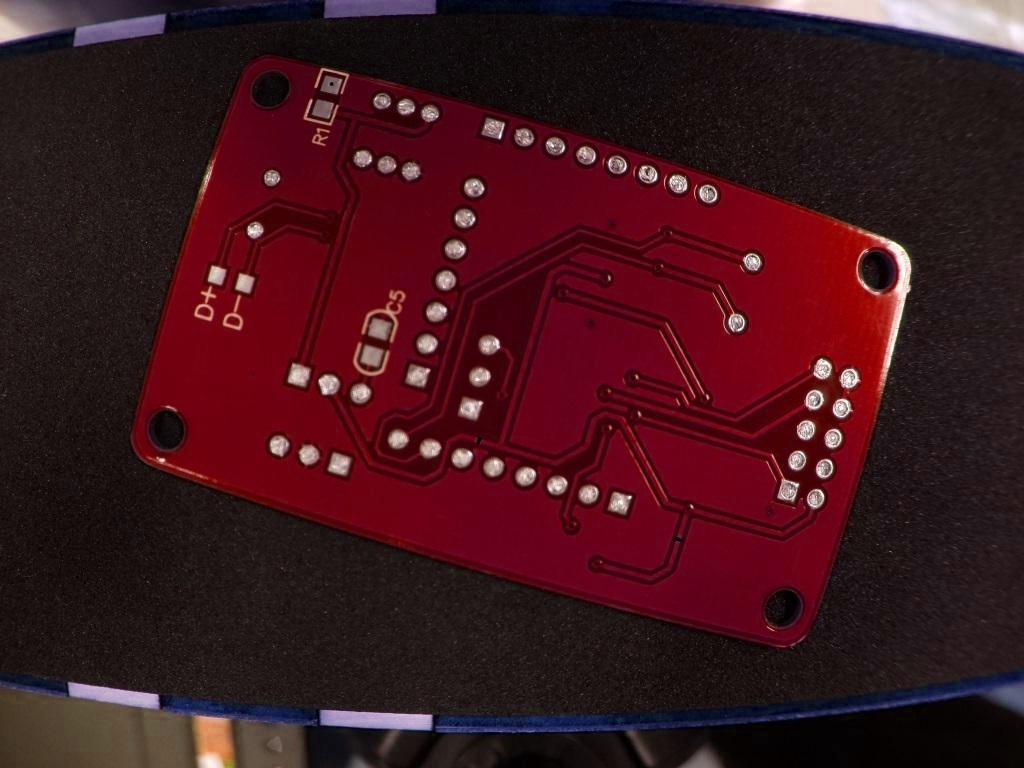

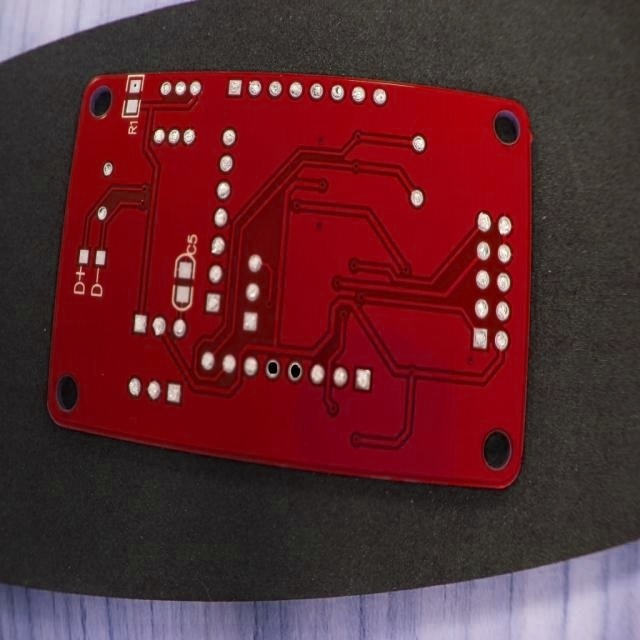

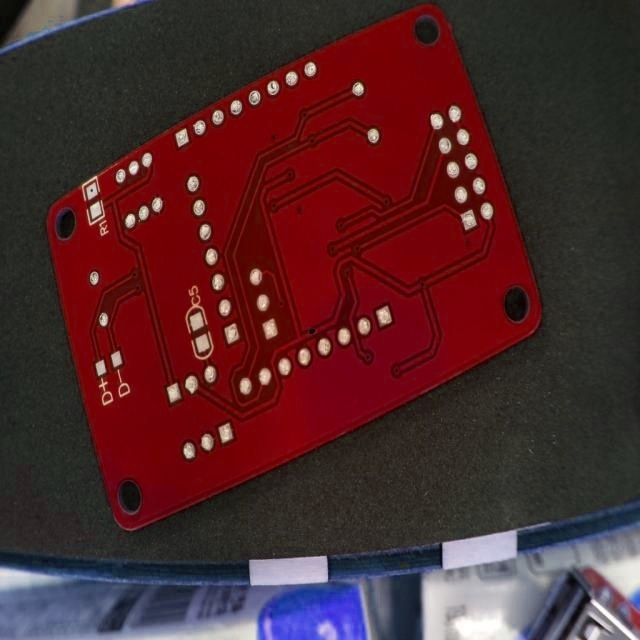

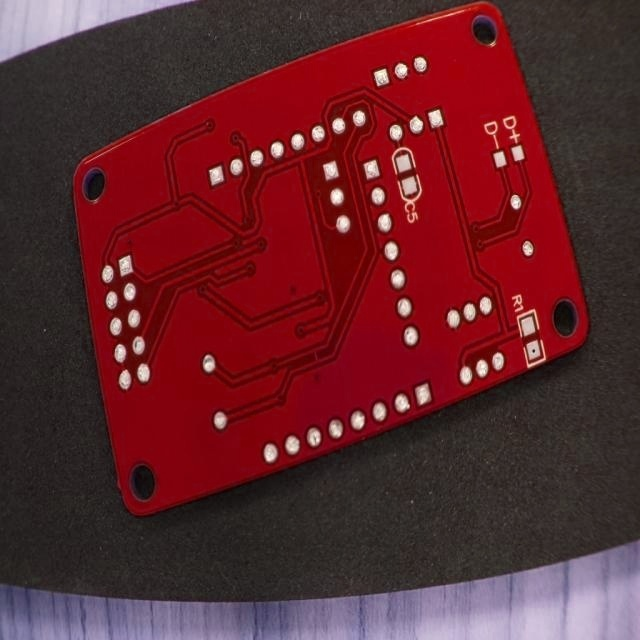

In [ ]:
import shutil
import os
import glob
import cv2
import yaml
from tqdm import tqdm
import random
from IPython.display import Image, display

# --- PASSO 1: LIMPEZA E PREPARAÇÃO (Começando do Zero) ---
print("1. Preparando o terreno...\n")

# Se já existir a pasta sabotada de uma tentativa anterior, apaga para não misturar
if os.path.exists("dataset_sabotado"):
    shutil.rmtree("dataset_sabotado")

# Cria a estrutura de pastas obrigatória do YOLO
os.makedirs("dataset_sabotado/images", exist_ok=True)
os.makedirs("dataset_sabotado/labels", exist_ok=True)

print("   -> Pasta 'dataset_sabotado/images' criada com sucesso.")
print("   -> Pasta 'dataset_sabotado/labels' criada com sucesso.\n")


# --- PASSO 2: GERAR AS IMAGENS "SABOTADAS" (Do Original -> Para o Final) ---
# Pega as imagens da pasta de teste do dataset que baixamos
pasta_origem_img = f'{dataset.location}/test/images/*.jpg'
todas_imagens = glob.glob(pasta_origem_img)

print(f"2. Processando {len(todas_imagens)} imagens originais...")
print("   (Alterando cor de Verde para Vermelho ...)")

for img_path in tqdm(todas_imagens):
    # Ler imagem original
    img = cv2.imread(img_path)
    if img is None: continue

    # Mudar cor (Simulando o novo lote de placas)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    # Adicionamos 100 à matiz para inverter a cor drasticamente
    hsv[:, :, 0] = (hsv[:, :, 0] + 100) % 180
    img_modificada = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

    # Salvar DIRETO na pasta sabotada
    nome_arquivo = os.path.basename(img_path)
    caminho_final = os.path.join("dataset_sabotado/images", nome_arquivo)
    cv2.imwrite(caminho_final, img_modificada)


# --- PASSO 3: COPIAR OS GABARITOS (LABELS) ---
print("\n\n3. Copiando os gabaritos (.txt)...")
# Como os defeitos estão no mesmo lugar (x,y), usamos os labels originais
pasta_origem_lbl = f'{dataset.location}/test/labels/*.txt'
todos_labels = glob.glob(pasta_origem_lbl)

for lbl_path in todos_labels:
    shutil.copy(lbl_path, "dataset_sabotado/labels/")

print(f"   -> {len(todos_labels)} arquivos de gabarito copiados.")


# --- PASSO 4: CRIAR O ARQUIVO DE CONFIGURAÇÃO (YAML) ---
print("\n4. Criando arquivo de configuração 'sabotado.yaml'...")

yaml_content = f"""
path: {os.path.abspath("dataset_sabotado")}
train: images
val: images
test: images

names:
  0: missing_hole
  1: mouse_bite
  2: open_circuit
  3: short
"""

with open("sabotado.yaml", "w") as f:
    f.write(yaml_content)


# --- PASSO 5: Cálculo do mAP, recall e precisão ---
print("\n5. Calculando métricas do Cenário B...\n")

# Importante: aqui é usado o baseline (modelv1), carregado de weights/baseline/best.pt
metrics_sabotado = modelv1.val(
    data='sabotado.yaml',
    split='test',
    project="runs/val",
    name="resultado_sabotagem"
)

print("\n" + "="*40)
print(f"RESULTADO OFICIAL (Cenário B):")
print(f"mAP50 = {metrics_sabotado.box.map50:.1%}")
print(f"Recall = {metrics_sabotado.box.mr:.1%}")
print(f"Precisao = {metrics_sabotado.box.mp:.1%}")
print("="*40)

if metrics_sabotado.box.map50 < 0.5:
    print("✅ SUCESSO: O mAP caiu drasticamente. Overfitting comprovado!")
else:
    print("⚠️ ATENÇÃO: O modelo foi bem mesmo com a cor errada.")

# --- PASSO 6: TESTAR VISUALMENTE AS PREDIÇÕES NO DATASET SABOTADO ---

print("\n6. Gerando predições visuais no dataset SABOTADO...\n")

# Rodar predição nas imagens da pasta sabotada
test_sabotado_imgs = glob.glob("dataset_sabotado/images/*.jpg")

results_sabotado = modelv1.predict(
    source=test_sabotado_imgs,
    conf=0.25,
    save=True,
    project="runs/detect",
    name="teste_sabotado"
)

# Mostrar algumas imagens
print("\n--- VISUALIZAÇÃO DAS PREDIÇÕES DO CENÁRIO SABOTADO ---")

# Escolher 10 imagens aleatórias
imgs_para_exibir = random.sample(test_sabotado_imgs, 10)

for img_path in imgs_para_exibir:
    nome = os.path.basename(img_path)
    caminho_pred = f"runs/detect/teste_sabotado/{nome}"
    display(Image(filename=caminho_pred, width=640))
